# Notebook 01: physical interactions and track lengths

This notebook reads the physical stage of a Geant4-DNA dump written by `sim.exe`: how many discrete G4DNA process firings occurred (`Dump.physical_interactions(per_event=True)`) and how long the primary and secondary electron tracks were (`Dump.track_lengths()`).

The default dump is a tiny, seeded run (10 keV electrons, two events). Everything below is a **workflow demonstration**, not a converged result. Run the cells from top to bottom in a fresh kernel; edit `IRT_DUMP` in the next cell to inspect other output.

In [1]:
from pathlib import Path
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from g4utils.DnaChem import Dump

dev_dir = os.environ.get('DEV_DIR')
if not dev_dir:
    raise RuntimeError(
        'DEV_DIR is unset. Run ~/dotfiles/scripts/windows/setup-dev-env.ps1 and restart the shell before using this notebook.'
    )
DEV_DIR = Path(dev_dir)

DEFAULT_RUN_ROOT = (
    DEV_DIR / 'GEANT4' / 'SIM' / 'dnachem-min'
    / '.scratch' / 'tests'
    / '2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the'
)

# Edit this path for a different dump (unprefixed, with its own Manifest.json).
IRT_DUMP = DEFAULT_RUN_ROOT / 'irt'

README_HINT = 'See notebooks/README.md ("Reproduce the runs") to regenerate the demonstration data.'

missing_api = [n for n in ('from_manifest', 'physical_interactions', 'track_lengths') if not hasattr(Dump, n)]
if missing_api:
    raise ImportError(f'The installed G4Utils lacks Dump.{missing_api}. {README_HINT}')
manifest_file = IRT_DUMP / 'Manifest.json'
if not manifest_file.is_file() or manifest_file.stat().st_size == 0:
    raise FileNotFoundError(f'No usable Manifest.json at {manifest_file}. Edit IRT_DUMP or regenerate. {README_HINT}')

dump = Dump.from_manifest(manifest_file)
print(f'Dump: {dump.path.resolve()}')

Dump: C:\DEV\GEANT4\SIM\dnachem-min\.scratch\tests\2026-11-03__read-notebooks-plan.md-and-implement-1-establish-the\irt


## 1. Discrete process firings

`physical_interactions(per_event=True)` returns one row per process label with the raw total `count` and `count_per_event = count / totalEvents`. These are **discrete G4DNA process firings** (one count each time a G4DNA process defines a step), **not track histories**: a single track fires many processes, and continuous transport steps are not counted. `count_per_event` is a mean firing count, not a G-value.

,label,count,count_per_event
0,e-_G4DNAElastic,51251,25625.5
1,e-_G4DNAVibExcitation,5737,2868.5
2,e-_G4DNAIonisation,1014,507.0
3,e-_G4DNAElectronSolvation,999,499.5
4,e-_G4DNAExcitation,122,61.0
5,e-_G4DNAAttachment,17,8.5


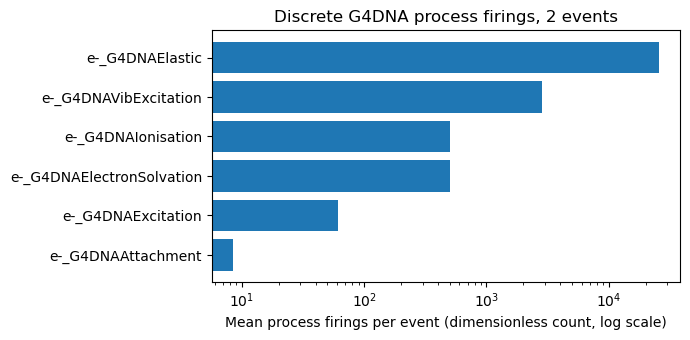

In [2]:
phys = dump.physical_interactions(per_event=True)
assert not phys.empty, 'No physical interaction counts in this dump.'
assert (phys['count_per_event'] * phys['totalEvents'] - phys['count']).abs().max() < 1e-6
phys = phys.sort_values('count', ascending=True)
display(phys[['label', 'count', 'count_per_event']].sort_values('count', ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh(phys['label'], phys['count_per_event'], color='tab:blue')
ax.set_xscale('log')
ax.set_xlabel('Mean process firings per event (dimensionless count, log scale)')
ax.set_title(f"Discrete G4DNA process firings, {int(phys['totalEvents'].iloc[0])} events")
fig.tight_layout()
plt.show()

## 2. Primary and secondary track lengths

`track_lengths()` returns one row per event with lengths in **nm** and kinetic energies in **keV**. Only non-aborted events get a row, so the table can have fewer rows than the events simulated; compare with `totalEvents` below. `primaryEnd` is `stopped`, `escaped` or `killed`.

Track rows: 2 of 2 simulated events (aborted events have no row)


,run,event,primaryLength_nm,primaryEkin0_keV,primaryEkinEnd_keV,primaryEnd,secondaryFirstGen_nm,nSecondaryFirstGen,secondaryAll_nm,nSecondaryAll
0,0,0,3940.635938,10.0,0.000025,stopped,4192.985256,226,6309.350231,511
1,0,1,2534.414142,10.0,0.000025,stopped,3655.026025,203,6768.150826,503


,events
primaryEnd,
stopped,2


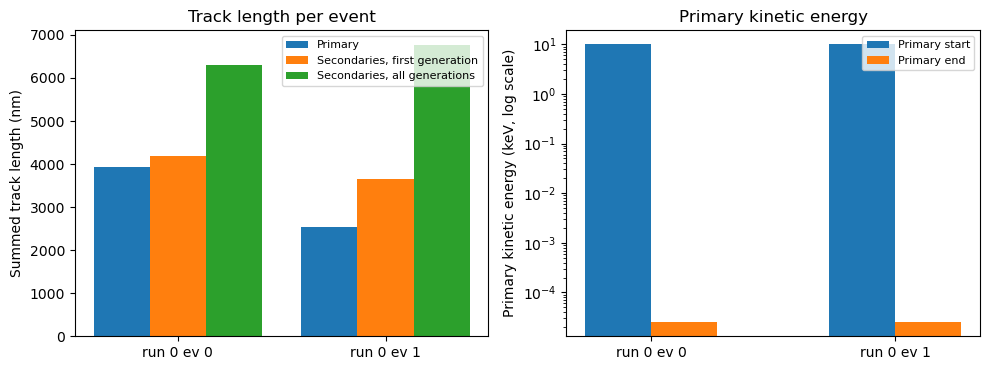

In [3]:
tracks = dump.track_lengths()
total_events = int(tracks['totalEvents'].iloc[0]) if not tracks.empty else int(phys['totalEvents'].iloc[0])
print(f'Track rows: {len(tracks)} of {total_events} simulated events (aborted events have no row)')
cols = ['run', 'event', 'primaryLength_nm', 'primaryEkin0_keV', 'primaryEkinEnd_keV', 'primaryEnd',
        'secondaryFirstGen_nm', 'nSecondaryFirstGen', 'secondaryAll_nm', 'nSecondaryAll']
display(tracks[cols])
display(tracks['primaryEnd'].value_counts().rename('events').to_frame())

tracks = tracks.assign(label=[f'run {r} ev {e}' for r, e in zip(tracks['run'], tracks['event'])])
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x = range(len(tracks))
w = 0.27
axes[0].bar([i - w for i in x], tracks['primaryLength_nm'], w, label='Primary')
axes[0].bar(list(x), tracks['secondaryFirstGen_nm'], w, label='Secondaries, first generation')
axes[0].bar([i + w for i in x], tracks['secondaryAll_nm'], w, label='Secondaries, all generations')
axes[0].set_xticks(list(x)); axes[0].set_xticklabels(tracks['label'])
axes[0].set_ylabel('Summed track length (nm)')
axes[0].set_title('Track length per event')
axes[0].legend(fontsize=8)
axes[1].bar([i - w / 2 for i in x], tracks['primaryEkin0_keV'], w, label='Primary start')
axes[1].bar([i + w / 2 for i in x], tracks['primaryEkinEnd_keV'], w, label='Primary end')
axes[1].set_yscale('log')
axes[1].set_xticks(list(x)); axes[1].set_xticklabels(tracks['label'])
axes[1].set_ylabel('Primary kinetic energy (keV, log scale)')
axes[1].set_title('Primary kinetic energy')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Reading notes

- Process counts are discrete G4DNA process firings (mostly elastic and vibrational steps at these energies), not track histories and not energy deposits.
- Track rows exclude aborted events; the row count can be below `totalEvents`.
- Secondary lengths are sums over many electrons (`nSecondary*` gives their number), so they can exceed the primary length.
- With two events these numbers carry large statistical uncertainty; use many events for any physical conclusion.